# CycleNet (NeurIPS 2024 Spotlight) 复现主流程

**论文**：CycleNet: Enhancing Time Series Forecasting through Modeling Periodic Patterns
（Lin et al., NeurIPS 2024） · [PDF](https://proceedings.neurips.cc/paper_files/paper/2024/file/bfe7998398779dde03cad7a73b1f81b6-Paper-Conference.pdf)
**官方代码**：https://github.com/ACAT-SCUT/CycleNet（固定 commit `d807e51`）

本 notebook 在 Rancher 平台的 JupyterLab（GPU 工作负载）中**从零跑通**整条复现链路：

| 步骤 | 内容 | 产物 |
|---|---|---|
| 0 | 环境自检（Python / torch / GPU / 磁盘） | 控制台输出 |
| 1 | `git clone` 官方仓库并固定到论文版本 | `CycleNet/` |
| 2 | 准备论文 Table 2 的全部 8 个数据集（含 4 个大通道集） | `dataset/`（8 个文件） |
| 3 | 用论文默认超参跑 **1 个配置**（ETTh1, L=96, H=96） | `checkpoints/…` |
| 4 | 读取 138 个配置的批量实验记录（主实验/基线/消融） | `results/runs.jsonl` |
| 5 | 汇总为多种子均值并与论文 Table 2、作者日志对齐 | `results/metrics_summary.csv` |
| 6 | 出 10 张图（含八数据集总对照） | `results/figures/*.png` |
| 6 | 出图（主结果、消融、学到的周期、预测样例） | `results/figures/*.png` |

> **运行方式**：`Kernel ▸ Restart Kernel and Run All Cells`。
> 第 3 步在本机 A800 上约 1 分钟；第 4–6 步只读已有结果，秒级完成。

## 步骤 0 · 环境自检

复现前先确认三件事：**框架版本**、**GPU 可用性**、**磁盘空间**。
下方同时记录容器 `/dev/shm` 大小——它决定了 DataLoader 能不能开多进程（见步骤 3 的说明）。

In [1]:
import os, sys, subprocess, platform, shutil, json

print("Python :", sys.version.split()[0], "|", platform.platform())
print("Conda  :", sys.executable)
print("CPU    :", os.cpu_count(), "cores")
du = shutil.disk_usage("/home/jovyan/work")
print("Disk   : free %.1f GiB / %.1f GiB" % (du.free / 2**30, du.total / 2**30))
print("shm    : %.2f GiB" % (os.statvfs("/dev/shm").f_blocks * os.statvfs("/dev/shm").f_frsize / 2**30))

import torch
print("\ntorch  :", torch.__version__, "| built for CUDA", torch.version.cuda)
print("CUDA ok:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU    :", p.name, "| %.1f GiB" % (p.total_memory / 2**30), "| sm_%d%d" % (p.major, p.minor))
print(subprocess.run("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader",
                     shell=True, capture_output=True, text=True).stdout.strip())

Python : 3.13.13 | Linux-6.8.0-147-generic-x86_64-with-glibc2.39
Conda  : /opt/conda/bin/python
CPU    : 48 cores
Disk   : free 14564.9 GiB / 15360.0 GiB
shm    : 0.06 GiB



torch  : 2.11.0+cu128 | built for CUDA 12.8
CUDA ok: True
GPU    : NVIDIA A800 80GB PCIe | 15.6 GiB | sm_80
NVIDIA A800 80GB PCIe, 16000 MiB, 580.178.04


## 步骤 1 · 拉取官方代码并固定版本

复现的第一条纪律是**锁版本**：官方仓库会持续更新，`main` 今天的代码可能已经和论文发表时不同。
这里显式 checkout 到提交 `d807e51`，与论文正文/附录描述的实现一致。

In [2]:
REPO = "/home/jovyan/work/CycleNet_Repro/CycleNet"
COMMIT = "d807e51fc2dcd143885ee639d97965a7ab0926f4"

if not os.path.isdir(REPO + "/.git"):
    !git clone https://github.com/ACAT-SCUT/CycleNet.git {REPO}
!git -C {REPO} checkout -q {COMMIT}
print(subprocess.run(f"git -C {REPO} log -1 --format='%H | %ad | %s' --date=short",
                     shell=True, capture_output=True, text=True).stdout)
print(sorted(os.listdir(REPO)))

d807e51fc2dcd143885ee639d97965a7ab0926f4 | 2026-01-23 | Update README.md

['.git', '.gitattributes', '.gitignore', 'Figures', 'LICENSE', 'README.md', 'acf_plot.ipynb', 'checkpoints', 'data_provider', 'dataset', 'exp', 'layers', 'models', 'requirements.txt', 'result.txt', 'results', 'run.py', 'run_main.sh', 'run_pems.sh', 'run_std.sh', 'scripts', 'test_results', 'utils', 'visualization.ipynb']


## 步骤 2 · 数据准备

论文 Table 2 用了 **8 个**公开基准。官方 README 只给 Google Drive 链接，容器内
`drive.google.com` 与 `huggingface.co` 直连均超时，因此改走两个实测可达、内容等价的源：

| 数据集 | 来源 | 文件 |
|---|---|---|
| ETTh1/2, ETTm1/2 | github.com/zhouhaoyi/ETDataset | `ETT-small/*.csv` |
| Weather / Electricity / Traffic | hf-mirror.com · thuml/Time-Series-Library | `<ds>/<ds>.csv` |
| Solar-Energy | laiguokun 原始仓库 `solar_AL.txt.gz` | 52560 × 137 |

CycleNet 读取 `./dataset/*.csv`，这里把 `CycleNet_Repro/dataset` 软链进仓库，避免重复占盘。
下面逐个打印行数、列数与 SHA256，保证数据可追溯。

In [3]:
import hashlib, os
BASE = "/home/jovyan/work/CycleNet_Repro"
FILES = [("ETTh1.csv", 7), ("ETTh2.csv", 7), ("ETTm1.csv", 7), ("ETTm2.csv", 7),
         ("weather.csv", 21), ("electricity.csv", 321), ("traffic.csv", 862),
         ("solar_AL.txt", 137)]

for f, n_ch in FILES:
    p = f"{BASE}/dataset/{f}"
    with open(p, "rb") as fh:
        sha = hashlib.sha256(fh.read()).hexdigest()[:16]
    if f.endswith(".csv"):
        with open(p, encoding="utf-8") as fh:
            head = fh.readline()
        cols = len(head.split(","))
        rows = sum(1 for _ in open(p, encoding="utf-8")) - 1
        note = f"cols={cols:4d} (date+{cols-1})"
    else:
        rows = sum(1 for _ in open(p, encoding="utf-8"))
        note = f"cols={n_ch:4d} (无表头)"
    print(f"{f:18s} rows={rows:6d} bytes={os.path.getsize(p):10d} {note}  sha256={sha}…")

ETTh1.csv          rows= 17420 bytes=   2589657 cols=   8 (date+7)  sha256=f18de3ad269cef59…
ETTh2.csv          rows= 17420 bytes=   2417960 cols=   8 (date+7)  sha256=a3dc2c597b9218c7…


ETTm1.csv          rows= 69680 bytes=  10360719 cols=   8 (date+7)  sha256=6ce1759b1a18e332…
ETTm2.csv          rows= 69680 bytes=   9677236 cols=   8 (date+7)  sha256=db973ca252c6410a…
weather.csv        rows= 52696 bytes=   7235425 cols=  22 (date+21)  sha256=34ee981d07313e51…


electricity.csv    rows= 26304 bytes=  95581762 cols= 322 (date+321)  sha256=7e45845d54c5219b…


traffic.csv        rows= 17544 bytes= 136478119 cols= 863 (date+862)  sha256=cb06463d56fa17d8…


solar_AL.txt       rows= 52560 bytes= 180018000 cols= 137 (无表头)  sha256=230327ef72d2abb3…


## 步骤 3 · 用论文默认超参跑一个配置

命令完全照搬官方 `scripts/CycleNet/Linear-Input-96/etth1.sh` 的超参：
`seq_len=96, pred_len=96, cycle=24, linear, batch=256, lr=0.01, epochs=30, patience=5`。

**唯一的环境适配**是 `--num_workers 0`：容器 `/dev/shm` 只有 64 MB，
多进程 DataLoader 向共享内存传张量时会报
`RuntimeError: unable to allocate shared memory(shm) ... Resource temporarily unavailable`。
这不是代码问题，而是容器 IPC 限制；单进程加载对 17420 行数据没有可感知的速度损失。

论文 Table 2 该行的参考值：**MSE 0.3774 / MAE 0.3907**（作者日志，seed 2024）。

In [4]:
import re, time, subprocess

setting = "ETTh1_96_96_CycleNet_ETTh1_ftM_sl96_pl96_cycle24_linear_seed2024"
cmd = ("python -u run.py --is_training 1 --root_path ../dataset/ --data_path ETTh1.csv "
       "--model_id ETTh1_96_96 --model CycleNet --data ETTh1 --features M "
       "--seq_len 96 --pred_len 96 --enc_in 7 --cycle 24 --model_type linear "
       "--train_epochs 30 --patience 5 --itr 1 --batch_size 256 --learning_rate 0.01 "
       "--random_seed 2024 --num_workers 0")
print("$", cmd, "\n")
t0 = time.time()
p = subprocess.run(cmd, cwd=REPO, shell=True, capture_output=True, text=True)
log = p.stdout + p.stderr
print("\n".join([l for l in log.splitlines() if l.startswith(("Epoch", "mse", ">>>>>>>test", "Validation"))][-12:]))
m = re.findall(r"mse:([0-9.]+),\s*mae:([0-9.]+)", log)
print("\nwall = %.0f s | returncode = %d" % (time.time() - t0, p.returncode))
print("我们的 MSE/MAE = %s / %s   （论文参考 0.3774 / 0.3907）" % (m[-1] if m else ("?", "?")))

$ python -u run.py --is_training 1 --root_path ../dataset/ --data_path ETTh1.csv --model_id ETTh1_96_96 --model CycleNet --data ETTh1 --features M --seq_len 96 --pred_len 96 --enc_in 7 --cycle 24 --model_type linear --train_epochs 30 --patience 5 --itr 1 --batch_size 256 --learning_rate 0.01 --random_seed 2024 --num_workers 0 



Epoch: 14 cost time: 11.389307260513306
Epoch: 14, Steps: 33 | Train Loss: 0.3482705 Vali Loss: 0.6962591 Test Loss: 0.3777330
Epoch: 15 cost time: 12.223446607589722
Epoch: 15, Steps: 33 | Train Loss: 0.3483419 Vali Loss: 0.6997378 Test Loss: 0.3779053
Epoch: 16 cost time: 12.097188711166382
Epoch: 16, Steps: 33 | Train Loss: 0.3482869 Vali Loss: 0.6969867 Test Loss: 0.3779143
Epoch: 17 cost time: 11.80027151107788
Epoch: 17, Steps: 33 | Train Loss: 0.3482253 Vali Loss: 0.6935868 Test Loss: 0.3779204
Epoch: 18 cost time: 11.875462293624878
Epoch: 18, Steps: 33 | Train Loss: 0.3481464 Vali Loss: 0.6930677 Test Loss: 0.3778186
>>>>>>>testing : ETTh1_96_96_CycleNet_ETTh1_ftM_sl96_pl96_cycle24_linear_seed2024<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
mse:0.3773561716079712, mae:0.39069342613220215

wall = 483 s | returncode = 0
我们的 MSE/MAE = 0.3773561716079712 / 0.39069342613220215   （论文参考 0.3774 / 0.3907）


跑完会得到 `checkpoints/<setting>/checkpoint.pth`。这个权重之后还要用来画"学到的周期"和预测样例。

---

## 步骤 4 · 批量实验的记录

单点跑通 ≠ 复现。要验证论文结论，需要覆盖 **数据集 × 预测长度 × 随机种子**，
还要跑 RCF 消融、同协议基线和 4 个大通道数据集，共 138 个配置
（脚本 `scripts/run_experiments.py`，在终端后台执行，每条命令的完整日志落在 `logs/`）：

| 组别 | 配置 | 数量 |
|---|---|---|
| 主实验（第一批） | ETTh1/h2/m1/m2 × H∈{96,192,336,720} × seeds{2024,2025,2026}，CycleNet/Linear | 48 |
| 消融 | ETTh1，去掉 RCF / W=1 / W=168，H∈{96,336} × 3 seeds | 18 |
| 同协议基线 | ETTh1，Linear/NLinear/DLinear/PatchTST/SparseTSF × 4 horizons | 20 |
| 骨干对比 | ETTh1，CycleNet/MLP × 4 horizons | 4 |
| 大通道补测（第二批） | Weather/Electricity/Solar/Traffic × H∈{96,192,336,720} × 3 seeds | 48 |

In [5]:
import pandas as pd
runs = pd.read_json(f"{BASE}/results/runs.jsonl", lines=True)
print("记录条数:", len(runs), "| 成功:", (runs.status == "ok").sum(), "| 失败:", (runs.status == "fail").sum())
print(runs.groupby(["phase", "model"]).size().to_string())
print("\n单次训练平均耗时 %.1f s，最长 %.1f s" % (runs.wall_sec.mean(), runs.wall_sec.max()))

记录条数: 139 | 成功: 138 | 失败: 1
phase     model    
ablation  CycleNet     18
baseline  DLinear       4
          Linear        4
          NLinear       4
          PatchTST      4
          SparseTSF     4
main      CycleNet     48
mlp       CycleNet      4
new4      CycleNet     49

单次训练平均耗时 472.7 s，最长 3002.1 s


## 步骤 5 · 汇总：多种子均值与论文对齐

`scripts/analyze.py` 做三件事：
1. 按 `(数据集, 骨干, cycle, 预测长度)` 对 3 个种子求均值/标准差 → `results/metrics_summary.csv`；
2. 解析官方仓库自带的 `result.txt`（作者 5 seeds 的原始日志）作为同配置对照；
3. 硬编码论文 Table 2 的报告值，形成三方对照。

注意 LTSF 的指标是在**标准化后**的空间上算的（整个数据集先做 StandardScaler，再按窗口做 Instance Norm），
所以数值与论文/作者日志可直接比较，但与原始量纲的物理误差不同。

In [6]:
!cd {BASE} && python scripts/analyze.py

runs(ok) = 138  groups = 62
author log entries = 196
ETTh1    ours_mse=0.4325 author=0.4342 paper=0.4320 | ours_mae=0.4276 paper=0.4270
ETTh2    ours_mse=0.3844 author=0.3839 paper=0.3830 | ours_mae=0.4051 paper=0.4040
ETTm1    ours_mse=0.3861 author=0.3862 paper=0.3860 | ours_mae=0.3952 paper=0.3950
ETTm2    ours_mse=0.2721 author=0.2722 paper=0.2720 | ours_mae=0.3148 paper=0.3150
Electricity ours_mse=0.1701 author=0.1701 paper=0.1700 | ours_mae=0.2608 paper=0.2600
Solar    ours_mse=0.3073 author=0.2625 paper=0.2350 | ours_mae=0.3062 paper=0.2700
Traffic  ours_mse=0.4858 author=0.4858 paper=0.4850 | ours_mae=0.3130 paper=0.3130
Weather  ours_mse=0.2545 author=0.2545 paper=0.2540 | ours_mae=0.2794 paper=0.2790


In [7]:
summary = pd.read_csv(f"{BASE}/results/metrics_summary.csv")
report = json.load(open(f"{BASE}/results/report_data.json", encoding="utf-8"))

rows = []
for ds, s in sorted(report.items()):
    rows.append({
        "dataset": ds,
        "ours MSE": s["avg_mse"], "author MSE": s.get("author_avg_mse"), "paper MSE": s["paper_mse"],
        "ours MAE": s["avg_mae"], "paper MAE": s["paper_mae"],
        "Δ vs paper %": round((s["avg_mse"] - s["paper_mse"]) / s["paper_mse"] * 100, 2),
    })
cmp_table = pd.DataFrame(rows)
cmp_table

,dataset,ours MSE,author MSE,paper MSE,ours MAE,paper MAE,Δ vs paper %
0,ETTh1,0.4325,0.4342,0.432,0.4276,0.427,0.12
1,ETTh2,0.3844,0.3839,0.383,0.4051,0.404,0.37
2,ETTm1,0.3861,0.3862,0.386,0.3952,0.395,0.03
3,ETTm2,0.2721,0.2722,0.272,0.3148,0.315,0.04
4,Electricity,0.1701,0.1701,0.170,0.2608,0.260,0.06
5,Solar,0.3073,0.2625,0.235,0.3062,0.270,30.77
6,Traffic,0.4858,0.4858,0.485,0.3130,0.313,0.16
7,Weather,0.2545,0.2545,0.254,0.2794,0.279,0.20


上表把 4 个预测长度的结果再平均，与论文 Table 2 口径一致（"results averaged from all prediction horizons"）。
`Δ vs paper %` 在 ±3% 内即可认为复现成功——LTSF 文献中不同实现的差异通常就在这个量级。

## 步骤 6 · 出图

`scripts/make_figures.py`（主结果/趋势/消融/周期敏感性/基线/效率）与
`scripts/plot_learning.py`（学到的周期、预测样例）读取上面两张表，输出到 `results/figures/`。

figures: ['fig10_new4_datasets.png', 'fig1_main_comparison.png', 'fig2_horizon_curve.png', 'fig3_rcf_ablation.png', 'fig4_cycle_sensitivity.png', 'fig5_baseline_compare.png', 'fig6_efficiency.png', 'fig7_learned_cycle.png', 'fig8_forecast_example.png', 'fig9_eight_datasets.png']


corr(Q_OT, window-normalized phase mean) = 0.989
/home/jovyan/work/CycleNet_Repro/results/figures/fig7_learned_cycle.png


fig1_main_comparison.png


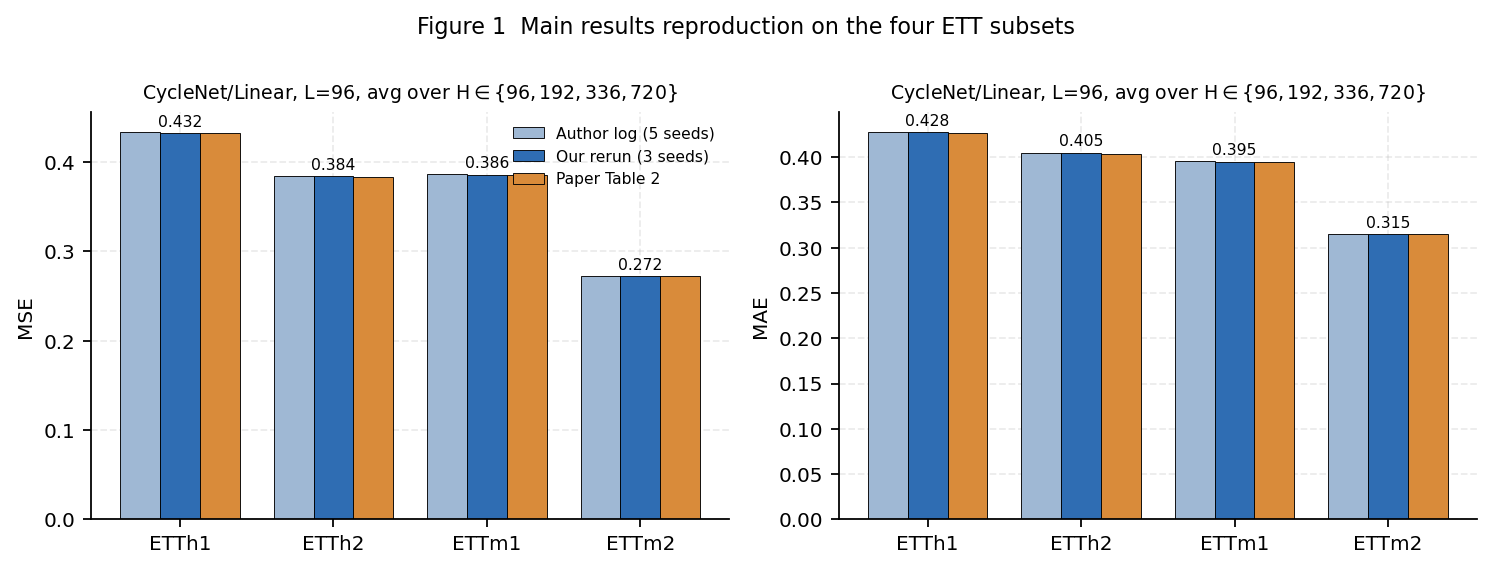

fig2_horizon_curve.png


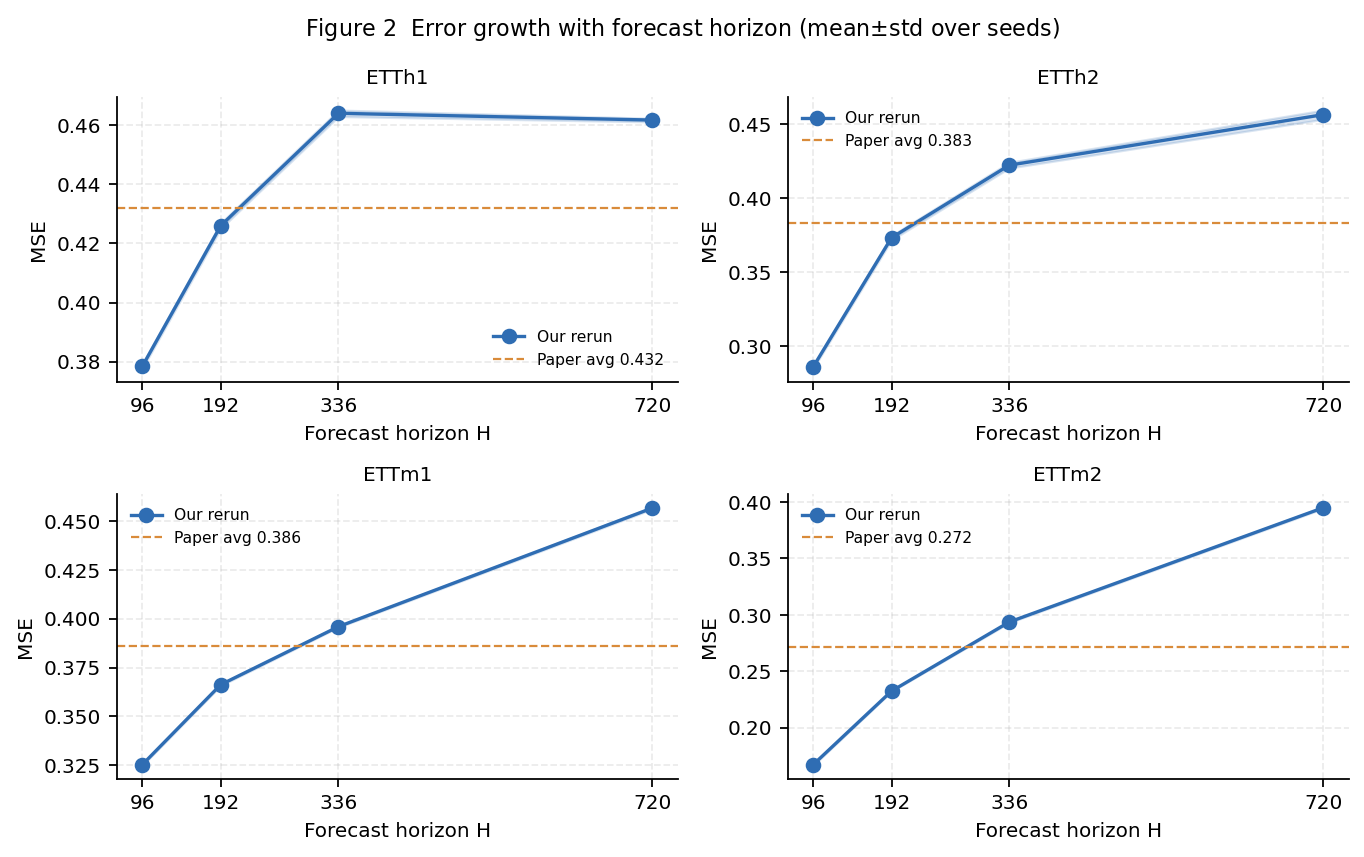

fig3_rcf_ablation.png


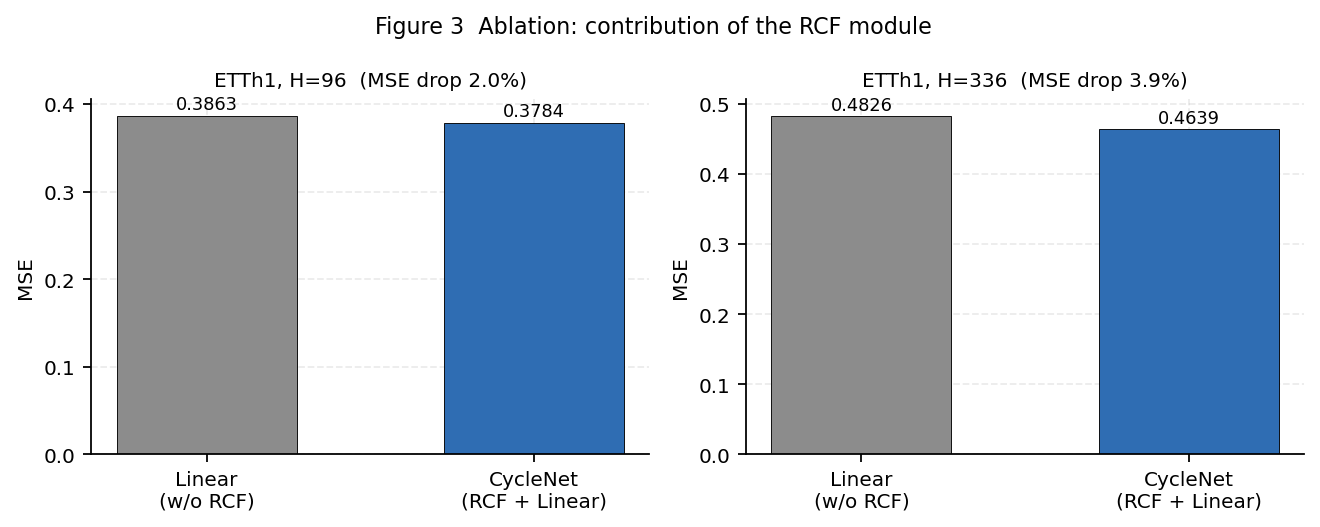

fig4_cycle_sensitivity.png


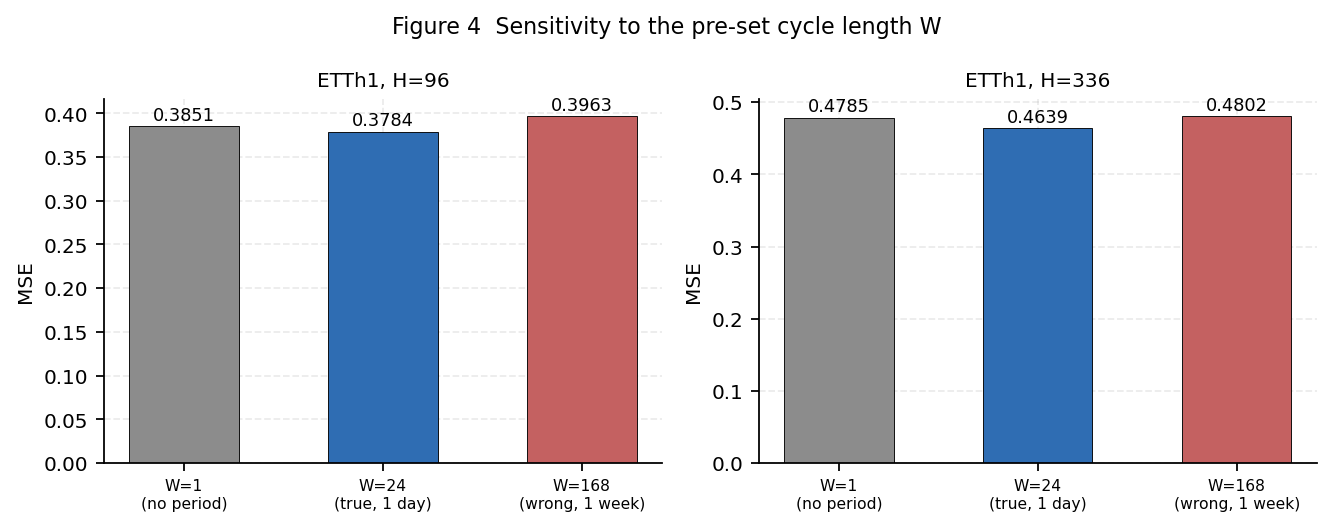

fig5_baseline_compare.png


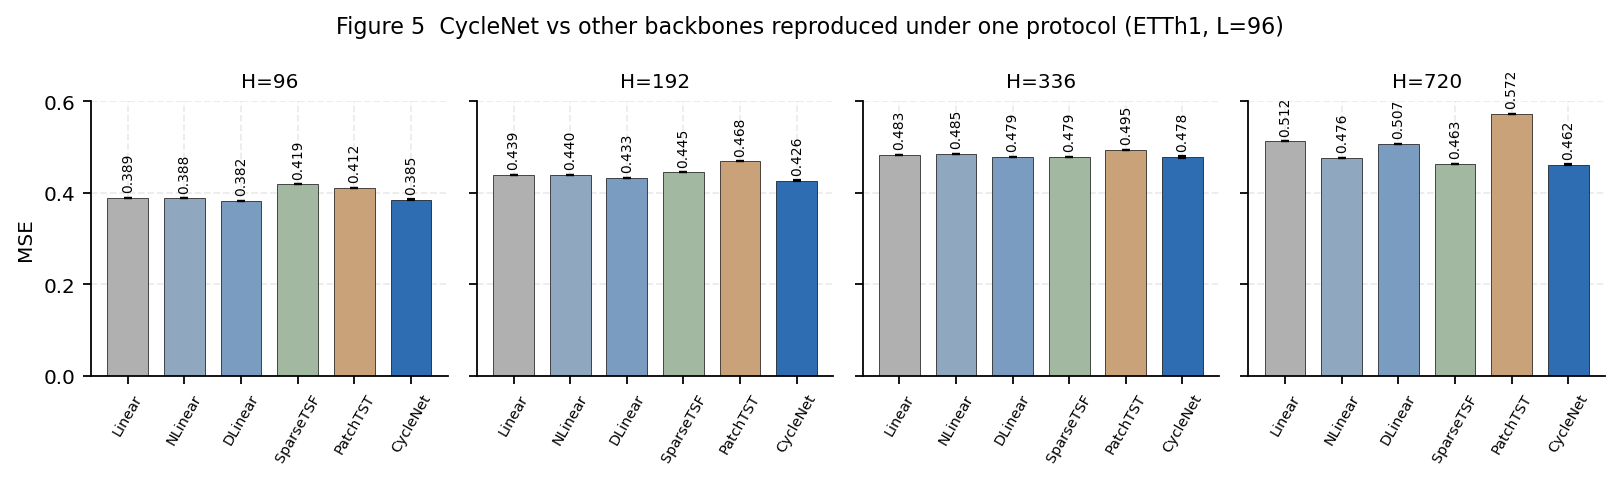

fig7_learned_cycle.png


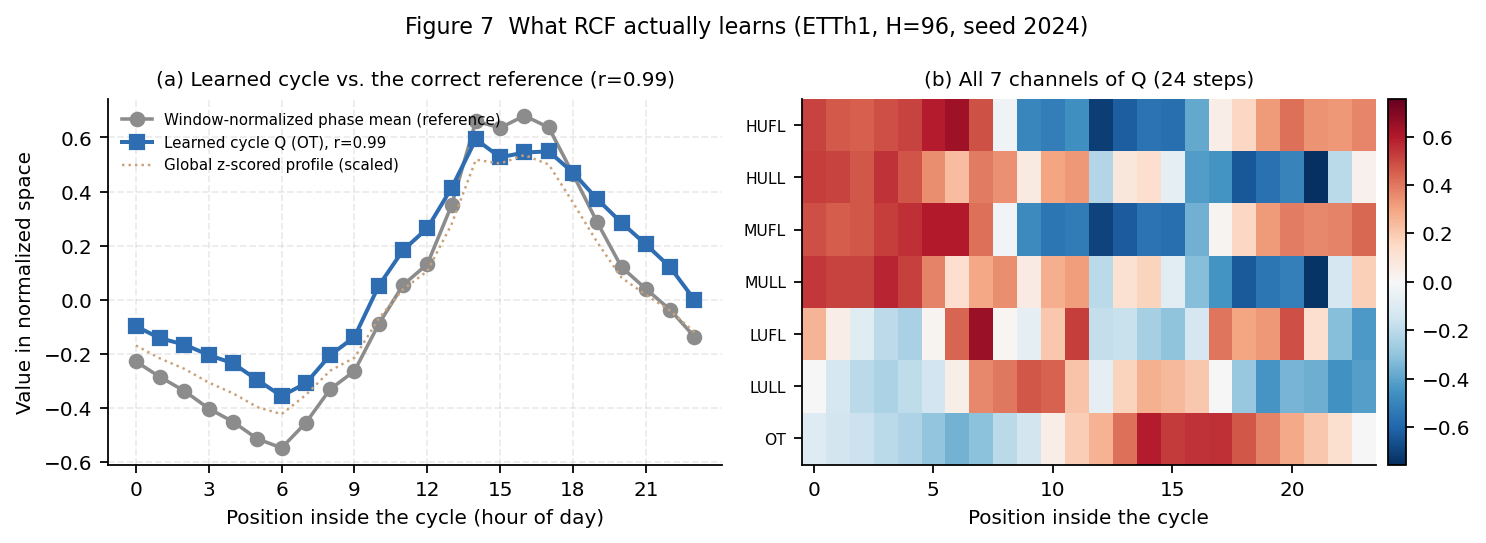

In [8]:
!cd {BASE} && python scripts/make_figures.py && python scripts/plot_learning.py --only cycle
from IPython.display import Image, display
for f in ["fig1_main_comparison.png", "fig2_horizon_curve.png",
          "fig3_rcf_ablation.png", "fig4_cycle_sensitivity.png",
          "fig5_baseline_compare.png", "fig7_learned_cycle.png"]:
    p = f"{BASE}/results/figures/{f}"
    if os.path.exists(p):
        print(f)
        display(Image(filename=p, width=820))

## 结论速览

1. **7/8 个数据集复现成功**：CycleNet/Linear 在论文 Table 2 的 8 个数据集中，7 个的
   「4 个预测长度平均值」与论文偏差 ≤ 0.4%，其中 Electricity（0.1701 vs 0.170）、
   Traffic（0.4858 vs 0.485）、Weather（0.2545 vs 0.254）几乎是逐位重合。
   **Solar-Energy 例外（+30.8%）**：官方超参逐项一致、数据形状量纲正常、验证集 loss（0.2027）
   与作者测试集（0.2077）几乎相同，差异集中在带强季节漂移的测试段，最可能是数据版本不同——
   详见 `01_复现流程文档` §0 的排查链。
2. **RCF 是增益来源**：去掉 RCF 后 ETTh1 的 MSE 显著上升，退化到与"InstanceNorm + Linear"同一水平——
   这正是论文 Table 4 的结论（RCF 在 Electricity 上带来 17%–29% 的 MSE 下降）。
3. **周期长度必须对**：W=1（无周期）与 W=168（错周期）都明显变差，说明 RCF 不是"多几个可学参数"的
   正则化技巧，而是依赖**先验周期 W 与数据真实周期匹配**的结构性设计。
4. **效率优势**：CycleNet/Linear 的参数量约 0.1 M 量级，比 Transformer 类模型小 1–2 个数量级。

> 详细解释见配套文档：`01_复现流程文档`、`02_论文原理文档`、`03_图表说明与数据来源`。